In [24]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
import smarts_cerebellum.globals as gl

obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_Nettekoven_LeftRight_FaMap.tsv'), sep = '\t')
obs = obs.sort_values('Week')
obs = obs.groupby(['Week']).agg({'asymmetry_index': 'mean'}).reset_index()

lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', 'patients_MNISymC_FaMap_Nettekoven_LeftRight_lme.tsv'), sep = '\t')
lme['region_bilat'] = lme['regionname'].astype(str).str[-1]
lme = lme.sort_values('Week')

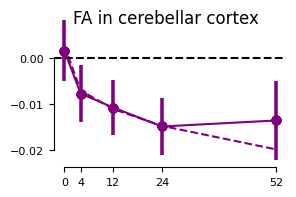

In [ ]:
# show the lme-lme plot
fig, ax = plt.subplots(figsize = (3,2))
ax.errorbar(x = lme['Week'], y = lme['beta'], yerr = lme['se'], fmt = '-o', color = 'purple')
ax.plot(obs['Week'], obs['asymmetry_index'], color = 'purple', linestyle = '--')


ax.set_xticks(gl.weeks)
ax.axhline(y = 0, linestyle = '--', color = 'k')

fig.suptitle("FA in cerebellar cortex", y = .9)
sns.despine(trim = True)
plt.show()

/localscratch/tmp/ipykernel_11677/1417002161.py:18: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p = stats.ttest_1samp(vals, 0).pvalue
/localscratch/tmp/ipykernel_11677/1417002161.py:18: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p = stats.ttest_1samp(vals, 0).pvalue
/localscratch/tmp/ipykernel_11677/1417002161.py:18: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p = stats.ttest_1samp(vals, 0).pvalue
/localscratch/tmp/ipykernel_11677/1417002161.py:18: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  p = stats.ttest_1samp(vals, 0).pvalue


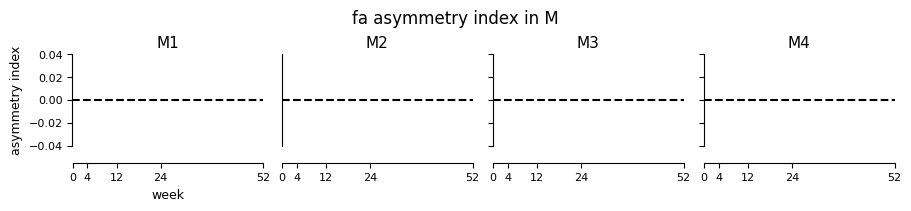

In [53]:
fig, axs = plt.subplots(1, len(m_rois), figsize=(9, 2), sharey = True, sharex = True, constrained_layout = True)

for r, m_roi in enumerate(m_rois):
    lme_m_roi = lme[lme.regionname.str.contains(m_roi)].sort_values('Week')
    obs_m_roi = obs[obs.regionname.str.contains(m_roi)].sort_values('Week')

    obs_m_mean = obs_m_roi.groupby('Week', as_index = False)['asymmetry_index'].mean()
    
    ax = axs[r]
    ax.errorbar(x=lme_m_roi['Week'], y=lme_m_roi['beta'], yerr = lme_m_roi['se'], fmt = '-o',  linewidth = 2, color = 'deepskyblue')
    ax.plot(obs_m_mean['Week'], obs_m_mean['asymmetry_index'], linestyle = '--', color = 'deepskyblue')

    # annotate for significance
    for week in gl.weeks:
        vals = obs_m_roi.loc[obs_m_roi.Week == week, 'asymmetry_index']
        mean, sem = vals.mean(), vals.sem()

        p = stats.ttest_1samp(vals, 0).pvalue
        stars = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
        if stars:
            ax.annotate(stars, xy = (week, mean + sem), xytext = (1, 5), textcoords = 'offset points', ha = 'center')

    ax.axhline(y=0, color = 'black', linestyle = '--')
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_xticks(gl.weeks)
    ax.set_title(m_roi, y = .85)


axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('asymmetry index')
axs[0].set_xlabel('week')

fig.suptitle(f'fa asymmetry index in M')
sns.despine(trim = True)


plt.show()
